# Time-Dependent Global Sensitivity Analysis with Active Subspaces for a Lithium Ion Battery Model

__Paul G. Constantine__, Department of Computer Science, University of Colorado Boulder

__Alireza Doostan__, Smead Aerospace Engineering Sciences Department, University of Colorado Boulder

Ryan Howard (2016 notebook)

Data: the battery simulations of Mohammad Hadigol, Kurt Maute and Alireza Doostan [[2]][R2], provided by Dr. Hadigol.

<br>

This notebook summarizes the active-subspace methodology and the results on the capacity and voltage of a lithium ion battery presented in [[1]][R1], and reproduces the paper's Figures 2–9 with the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy and matplotlib (see the repository's `requirements.txt`), and takes about a minute.

### Introduction

Lithium (Li) batteries are the most popular batteries for small electronics, but their use is limited by their short lifespan and safety concerns. The scale on which these batteries must be analyzed ranges from overall cell thickness (millimeters) to the thickness of constituent particles (nanometers) and many physical phenomena are present, such as transport, mechanical, and electrochemical processes. Accurately modelling these systems is challenging because there are often many input parameters whose exact values in practice are uncertain and simplifying assumptions must be made to make the complex physics tractable.

A method of addressing these challenges is _uncertainty quantification_ (UQ): using simulations to estimate the effects of our uncertainty about various aspects of our physical system. Traditional methods of UQ can be intractable with multiphysics models because the number of parameters required to characterize the models tends to be large and the number of model evaluations to explore a system's behavior grows exponentially with the number of parameters. If a simulation is expensive, it may be impossible to run it enough times for an exhaustive parameter study. One approach to solving this 'curse of dimensionality' is to lower the dimension of the problem. In this notebook, we'll describe a method of dimension reduction called _active subspaces_ and its performance on a model of Li batteries.

### Active Subspaces

##### Stationary Models

In this framework, we consider our normalized uncertain parameters, $\mathbf x\in R^m$, as random variables with a joint pdf $\rho(\mathbf x)$. Our model has a (scalar) quantity of interest (output), $f$, that depends on the values of the parameters: $f = f(\mathbf x)$. The active subspaces methodology is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\nabla f(\mathbf x)^T\rho(\mathbf x)\ d\mathbf x,
$$

where $\nabla f$ is the gradient of $f$ with respect to $\mathbf x$. This matrix is positive semidefinite, so it has an eigendecomposition:

$$
\mathbf C = \mathbf W\Lambda\mathbf W^T,\ \Lambda = \left[\begin{matrix}\lambda_1 & & \\ & \ddots & \\ & & \lambda_m\end{matrix}\right],\ \mathbf W = \left[\begin{matrix}\mathbf w_1 & \cdots & \mathbf w_m\end{matrix}\right],
$$

where the eigenvalues are in descending order. The eigenvalues satisfy the relationship $\lambda_i = \int(\nabla f^T\mathbf w_i)^2\rho\ d\mathbf x$. This means the $i^{th}$ eigenvalue is the average squared directional derivative of $f$ along $\mathbf w_i$; if an eigenvalue is relatively small, $f$ will be relatively flat in the direction defined by the corresponding eigenvector. If $\lambda_n > \lambda_{n+1}$ for some $n$, we can partition the decomposition as:

$$
\Lambda = \left[\begin{matrix}\Lambda_1 & \\ & \Lambda_2\end{matrix}\right],\ \mathbf W =  \left[\begin{matrix}\mathbf W_1 & \mathbf W_2\end{matrix}\right],
$$

where $\Lambda_1$ contains the first $n$ eigenvalues and $\mathbf W_1$ the corresponding vectors. If $\Lambda_2$'s eigenvalues are much smaller than those of $\Lambda_1$, then $f$ is likely relatively constant in the space spanned by $\mathbf W_2$ and we could approximate: $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x)$ with some $g:R^n\rightarrow R$. We call $\mathbf y = \mathbf W_1^T\mathbf x$ the active variables; the subspace spanned by the columns of $\mathbf W_1$ is the active subspace.

Computing $\mathbf C$ analytically is generally impossible. If gradients are available, one can use a numerical integration rule to approximate $\mathbf C$ and its decomposition. Our model, however, does not give direct access to the gradient and it is too expensive to run for finite differences to be used to approximate gradients. A heuristic that can be used in such cases is based on a linear-model approximation of $f$: $f(\mathbf x) \approx a + \mathbf a^T\mathbf x \Rightarrow \nabla f \approx \mathbf a$. Then $\mathbf C \approx \int \mathbf a\mathbf a^T\rho(\mathbf x)\ d\mathbf x = \mathbf a\mathbf a^T = \mathbf w\lambda\mathbf w^T$, where $\lambda = ||\mathbf a||^2$ and $\mathbf w = \mathbf a/||\mathbf a||$. The purpose of this method is to identify $\mathbf w$ (the _single_ most important direction in the parameter space) rather than to approximate $f$; this method cannot identify higher-dimensional subspaces. We thus employ the algorithm ([[1]][R1] Algorithm 1): draw $\{\mathbf x_j\}_{j=1}^N$ from $\rho$ and compute $f_j = f(\mathbf x_j)\ \forall j$; compute the OLS estimates, $a^*$ and $\mathbf a^*$, of the linear model $f_j\approx a + \mathbf a^T\mathbf x_j$; and let $\mathbf w = \mathbf a^*/||\mathbf a^*||$. With this sign, $f$ increases along $\mathbf w$ on average.

We can easily see if we've found a 1-dimensional active subspace by creating a _summary plot_: a scatterplot of $\mathbf w^T\mathbf x_j$ vs $f_j$; if a tight univariate trend is present, we have likely discovered such a subspace. If the subspace is present, the components of $\mathbf w$ are a measure of global sensitivity; higher-magnitude components indicate relative sensitivity to the corresponding parameter. If the univariate trend is monotonic, the signs of components tell us whether increasing the corresponding parameter will increase or decrease output; for example, if the trend is monotonic increasing and a parameter has a positive component in $\mathbf w$, increasing it will increase the output.

A second heuristic ([[1]][R1] Algorithm 2) fits a global quadratic model $f(\mathbf x)\approx c + \mathbf g^T\mathbf x + \frac12\mathbf x^T\mathbf H\mathbf x$ and takes the eigenpairs of $\int(\mathbf g + \mathbf H\mathbf x)(\mathbf g + \mathbf H\mathbf x)^T\rho\,d\mathbf x$. It needs more runs ($N > \binom{m+2}{2}$), but its eigenvalues show whether $f$ also varies along directions other than the first.

##### Time-Dependent Models

Suppose our model's output depends on parameters, $\mathbf x$, and time, $t$: $f = f(\mathbf x, t)$. One way we could construct active subspaces on such a model is to extend $\mathbf C$ as

$$
\mathbf C = \frac 1 T\int\left(\int\left[\begin{matrix}f_t(\mathbf x, t)^2 & f_t(\mathbf x, t)\nabla f(\mathbf x, t)^T \\ f_t(\mathbf x, t)\nabla f(\mathbf x, t) & \nabla f(\mathbf x, t)\nabla f(\mathbf x, t)^T\end{matrix}\right]\rho(\mathbf x)\ d\mathbf x\right)\ dt,
$$

where $f_t(\mathbf x, t)$ is the partial derivative of $f$ with respect to $t$. This matrix has a block structure: $\mathbf C = \left[\begin{matrix}a & \mathbf b^T\\\mathbf b & \mathbf D\end{matrix}\right]$. We could construct subspaces based on the eigenvalues of the block $\mathbf D$, essentially averaging a time-dependent version of $\mathbf C$ from the above section, or we could use this new $\mathbf C$'s Schur complement: $\mathbf C_S = \mathbf C - \frac 1 a\mathbf b\mathbf b^T$. However, the approach we choose to use is to treat the stationary-model $\mathbf C$ as a matrix whose elements depend on time:

$$
\mathbf C(t) = \int\nabla f(\mathbf x, t)\nabla f(\mathbf x, t)^T\rho(\mathbf x)\ d\mathbf x = \mathbf W(t)\Lambda(t)\mathbf W(t)^T.
$$

We can consider a discrete set of points in our time domain, $\{t_k\}_{k=1}^P$, and compute the eigendecomposition at each of these points to examine the time-dependence of the active subspace, or in our case, we can use the linear-model approximation algorithm at several points in time.

##### Assessing Uncertainty in the Active Subspace, and Limitations of Our Methods

We can assess variability in our estimate of $\mathbf w$ by examining the standard error of $\mathbf w$'s components acquired from a nonparametric bootstrap procedure. While the statistical interpretation of this method is absent since there is no random noise, high standard errors could still indicate that we don't have enough data to accurately estimate $\mathbf w$ or that a higher-dimensional subspace is required.

Estimating the active subspace is _extremely_ cheap in the sense that it can be done with far less than exhaustive sampling of the parameter space. However, this lack of exhaustive sampling can result in 'false positives' (our samples could erroneously indicate a subspace that actually doesn't exist) or 'false negatives' (our samples could be insufficient to find the subspace and make it appear that there is none). In practice, the authors of [[1]][R1] have never experienced such a false positive. They suspect this is because many physical models have outputs that vary smoothly with their inputs, so the dramatic local variation that could cause one seems largely absent from physics-based simulations ([[1]][R1] §2.8).

### References:

[[1]][R1] P.G. Constantine and A. Doostan. _Time-dependent global sensitivity analysis with active subspaces for a lithium ion battery model_. Stat. Anal. Data Min., 10(5):243–262, 2017. doi:10.1002/sam.11347 (arXiv:1606.08770)

[[2]][R2] M. Hadigol, K. Maute, and A. Doostan. _On uncertainty quantification of lithium-ion batteries: Application to an LiC$_6$/LiCoO$_2$ cell_. J. Power Sources, 300:507–524, 2015. doi:10.1016/j.jpowsour.2015.09.060

[[3]][R3] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[[4]][R4] P.G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, 2015. doi:10.1137/1.9781611973860

[R1]: https://doi.org/10.1002/sam.11347
[R2]: https://doi.org/10.1016/j.jpowsour.2015.09.060
[R3]: https://doi.org/10.1137/130916138
[R4]: https://doi.org/10.1137/1.9781611973860

### Acknowledgments

We thank Dr. Mohammad Hadigol for providing the Li battery data set. This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

The acknowledgments of the published paper [[1]][R1] (pp. 260–261) read: "We thank Dr. Mohammad Hadigol for providing us with the Li battery data set used in this work. This material is based upon (i) work of P.C. supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077 and the Defense Advanced Research Projects Agency's Enabling Quantification of Uncertainty in Physical Systems and (ii) work of A.D. supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, under Award Number DE-SC0006402 and NSF grant CMMI-1454601."

### The Lithium Battery Model

The model we use describes a Li battery as a cathode and an anode separated by a separator (Newman's porous-electrode model, as set up by Hadigol et al. [[2]](https://doi.org/10.1016/j.jpowsour.2015.09.060) for a LiC$_6$/LiCoO$_2$ cell). Electrical current is produced when Li$^+$ ions diffuse from the anode to the cathode through the separator and electrons flow through the external circuit, again from anode to cathode. We examine two quantities of interest output by the model: capacity as a function of voltage (voltage plays the role of time in the above discussion) and voltage as a function of time. The model has 19 input parameters, summarized in the table below from [[1]](https://doi.org/10.1002/sam.11347) Table 1. The rows are in the order of the data columns: input $j$ is column `X[:, j]`.

$j$ | Name | Symbol | Units | Nominal | Distribution
:--|:-----|:------:|:------|:--------|:------------
0 | Anode porosity | $\epsilon_a$ | — | 0.485 | $U(0.46, 0.51)$
1 | Separator porosity | $\epsilon_s$ | — | 0.724 | $U(0.63, 0.81)$
2 | Cathode porosity | $\epsilon_c$ | — | 0.385 | $U(0.36, 0.41)$
3 | Anode Bruggeman coefficient | brugg$_a$ | — | 4 | $U(3.8, 4.2)$
4 | Separator Bruggeman coefficient | brugg$_s$ | — | 4 | $U(3.2, 4.8)$
5 | Cathode Bruggeman coefficient | brugg$_c$ | — | 4 | $U(3.8, 4.2)$
6 | Li$^+$ transference number | $t_+^0$ | — | 0.363 | $U(0.345, 0.381)$
7 | Salt diffusion coefficient in liquid | $D$ | m$^2$ s$^{-1}$ | $7.5\times 10^{-10}$ | $U(6.75, 8.25)\times 10^{-10}$
8 | Anode solid diffusion coefficient | $D_a$ | m$^2$ s$^{-1}$ | $3.9\times 10^{-14}$ | $U(3.51, 4.29)\times 10^{-14}$
9 | Cathode solid diffusion coefficient | $D_c$ | m$^2$ s$^{-1}$ | $1.0\times 10^{-14}$ | $U(0.90, 1.10)\times 10^{-14}$
10 | Anode conductivity | $\sigma_a$ | S m$^{-1}$ | 100 | $U(90, 110)$
11 | Cathode conductivity | $\sigma_c$ | S m$^{-1}$ | 100 | $U(90, 110)$
12 | Anode reaction rate | $k_a$ | m$^4$ mol s (as printed) | $5.031\times 10^{-11}$ | $U(4.52, 5.53)\times 10^{-11}$
13 | Cathode reaction rate | $k_c$ | m$^4$ mol s (as printed) | $2.334\times 10^{-11}$ | $U(2.10, 2.56)\times 10^{-11}$
14 | Anode particle size | $r_a$ | μm | 2 | $N(2, 0.1354)$ in [[1]](https://doi.org/10.1002/sam.11347); see below
15 | Cathode particle size | $r_c$ | μm | 2 | $N(2, 0.3896)$ in [[1]](https://doi.org/10.1002/sam.11347); see below
16 | Anode length | $L_a$ | μm | 80 | $U(77, 83)$
17 | Separator length | $L_s$ | μm | 25 | $U(22, 28)$
18 | Cathode length | $L_c$ | μm | 88 | $U(85, 91)$

We examine our quantities of interest at three discharge rates: $0.25C$, $1C$, and $4C$. A $1C$ discharge drains the battery's nominal capacity in 1 h, $0.25C$ in about 4 h, and $4C$ in about 15 min. Our dataset has 3600 pairs of inputs/outputs for each discharge rate (very sparse for a 19-dimensional input space), totaling 10800 runs; the inputs are the same at every rate. Each run produces 50 voltage/capacity and 50 time/voltage pairs. The inputs are stored only after they were shifted and scaled to the hypercube $[-1,1]^{19}$, the coordinates the analysis uses. Each run stopped when the voltage reached the 2.8 V cutoff, and we reparameterize time: we let $t^* = 100$ at physical time 0 and $t^* = 0$ at the physical time when voltage reaches 2.8 V. The voltage columns are labeled $t^* = 99, 97, \dots, 1$ (column $k$ at $t^* = 99 - 2k$, as in the 2016 code), and the analysis uses columns 1 to 48 ($t^* = 97, \dots, 3$).

**About the data.** The notebook reads `battery_data.npz`, a lossless conversion (by `make_battery_npz.py`) of the inputs, voltage and capacity columns of Hadigol's three text files; `DATA.md` describes it. Three points are not settled:

- The capacity columns hold what appears to be elapsed discharge time in seconds. We convert it to capacity in mAh cm$^{-2}$, the unit of [[1]](https://doi.org/10.1002/sam.11347), with the 1C current density $I_{1C} = 30$ A m$^{-2}$ from the 2016 code: capacity $= (I/I_{1C})\,I_{1C}\,t/36000$. Both the meaning of the columns and $I_{1C}$ are inferred, not confirmed.
- [[1]](https://doi.org/10.1002/sam.11347) Table 1 gives Normal distributions for the particle sizes $r_a$ and $r_c$, but their stored values are spread uniformly over $[-1, 1]$ like the other 17 inputs (excess kurtosis printed below; a uniform variable has $-1.2$, a normal one $0$). Which one is right is not known; we analyze the data as stored.
- Two 4C runs end below the 2.8 V cutoff: their solver overshot it. We drop every run whose final voltage is more than 1 mV below the cutoff. This rule removes runs 1538 and 2969 at 4C, so $N = 3598$ there, and none at 0.25C and 1C. The 2016 code removed only run 1538, without comment; [[1]](https://doi.org/10.1002/sam.11347) says every fit used $N = 3600$.

In [1]:
%matplotlib inline
import time
import warnings
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import battery_figs as bf

t_start = time.perf_counter()
plt.rcParams.update({'font.family': 'serif', 'font.size': 14})
rng = np.random.default_rng(2016)        # the only source of randomness in this notebook (the bootstrap)

with np.load(bf.DATA) as z:
    flagged = {rate: z[f'dropped_runs_{key}'] for rate, (key, _) in bf.RATES.items()}
X, F, grid = {}, {}, {}
for rate in bf.RATES:
    X_all, V_all, Q_all, vgrid = bf.load(rate)
    drop = bf.overshoot(V_all)
    v_end = V_all[:, -1]
    z_end = (v_end - v_end.mean()) / v_end.std()
    assert np.array_equal(np.flatnonzero(drop) + 1, flagged[rate])   # Run = row + 1; same rule as the npz flag
    assert np.array_equal(drop, np.abs(z_end) > 5)                   # an outlier rule picks the same runs
    X[rate] = X_all[~drop]
    F['capacity', rate], grid['capacity', rate] = Q_all[~drop], vgrid
    F['voltage', rate], grid['voltage', rate] = V_all[~drop], bf.TSTAR
    print(f'{rate}: N = {(~drop).sum()}, dropped runs {(np.flatnonzero(drop) + 1).tolist()} '
          f'(final voltage {np.round(v_end[drop], 3).tolist()} V, |z| {np.round(np.abs(z_end[drop]), 1).tolist()}); '
          f'capacity {Q_all.mean(0)[0]:.2f} mAh/cm^2 at {vgrid[0]:.2f} V to {Q_all.mean(0)[-1]:.2f} at {vgrid[-1]:.1f} V (means)')

kurt = ((X_all - X_all.mean(0))**4).mean(0) / X_all.var(0)**2 - 3
print(f'excess kurtosis of the 19 stored inputs: {kurt.min():.2f} to {kurt.max():.2f}; r_a {kurt[14]:.2f}, r_c {kurt[15]:.2f}')
QOIS = [(qoi, rate) for rate in bf.RATES for qoi in ('capacity', 'voltage')]

0.25C: N = 3600, dropped runs [] (final voltage [] V, |z| []); capacity 0.01 mAh/cm^2 at 4.13 V to 2.67 at 2.8 V (means)
1C: N = 3600, dropped runs [] (final voltage [] V, |z| []); capacity 0.02 mAh/cm^2 at 4.03 V to 2.65 at 2.8 V (means)
4C: N = 3598, dropped runs [1538, 2969] (final voltage [2.746, 2.791] V, |z| [59.2, 9.5]); capacity 0.04 mAh/cm^2 at 3.72 V to 1.01 at 2.8 V (means)
excess kurtosis of the 19 stored inputs: -1.23 to -1.18; r_a -1.22, r_c -1.20


### Algorithm 1 at every voltage and every $t^*$

For each quantity of interest (capacity or voltage, at each rate) we apply Algorithm 1 at each grid point: 50 voltages for capacity and 48 values of $t^*$ for voltage. In active_subspaces v1 this is `ac.active_subspace(estimator="ols", n=1)`, which returns $\mathbf w = \mathbf a^*/\|\mathbf a^*\|$ with the sign of [[1]](https://doi.org/10.1002/sam.11347), so that $f$ increases along $\mathbf w$.

The inputs are uniform, so the input space is the reference cube $[-1, 1]^{19}$ (`ac.Uniform.reference`). On a uniform space v1 warns `ValidityWarning` at every OLS call: the linear-model heuristic has no guarantee there (for Gaussian inputs, $\mathbf a^*$ estimates the average gradient). [[1]](https://doi.org/10.1002/sam.11347) uses it as a heuristic and checks it with summary plots and Algorithm 2, so `bf.weights` filters that one warning.

In [2]:
W = {}
for qoi, rate in QOIS:
    subs = bf.weights(X[rate], F[qoi, rate][:, bf.COLS[qoi]])
    W[qoi, rate] = np.array([s.W1[:, 0] for s in subs])     # one row per grid point
print(f'{sum(len(w) for w in W.values())} subspaces: {time.perf_counter() - t_start:.0f} s so far')

294 subspaces: 3 s so far


**Checks against the 2016 code.** The 2016 code computed $\mathbf w$ with `np.linalg.lstsq`. We repeat that computation and compare. We also check that $f$ increases along $\mathbf w$ (cov$(\mathbf X\mathbf w, f) > 0$) at every grid point, and measure what dropping run 2969, which the 2016 code kept, changes at 4C.

In [3]:
def algorithm1(X, f):
    """[1] Algorithm 1 as coded in 2016."""
    u = np.linalg.lstsq(np.hstack([np.ones((len(f), 1)), X]), f, rcond=None)[0][1:]
    return u / np.linalg.norm(u)


def at(key, c):
    """w at grid column c."""
    return W[key][bf.row(key[0], c)]


dev, cov_min = 0.0, np.inf
for (qoi, rate), Wk in W.items():
    Fk = F[qoi, rate][:, bf.COLS[qoi]]
    dev = max(dev, np.abs(Wk - np.array([algorithm1(X[rate], f) for f in Fk.T])).max())
    cov_min = min(cov_min, min(np.cov(X[rate] @ w, f)[0, 1] for w, f in zip(Wk, Fk.T)))
print(f'max |w(v1) - w(lstsq)| over all {sum(len(w) for w in W.values())} grid points: {dev:.1e}; '
      f'min cov(Xw, f) = {cov_min:.2e} > 0: {cov_min > 0}')

X4, V4, Q4, _ = bf.load('4C')
keep_2016 = np.arange(3600) != 1537                      # the 2016 rule: drop run 1538 only
for qoi, F4 in [('capacity', Q4), ('voltage', V4)]:
    W2016 = np.array([algorithm1(X4[keep_2016], f) for f in F4[keep_2016][:, bf.COLS[qoi]].T])
    print(f'4C {qoi}: dropping run 2969 as well changes w by at most {np.abs(W2016 - W[qoi, "4C"]).max():.1e}')


def top(key, c, k=4):
    w = at(key, c)
    return ', '.join(f'{bf.NAMES[j]} {w[j]:+.2f}' for j in np.argsort(-np.abs(w))[:k])


w = at(('capacity', '0.25C'), 38)
print(f'0.25C capacity at {grid["capacity", "0.25C"][38]:.2f} V: {top(("capacity", "0.25C"), 38, 2)}; '
      f'largest other |w_j| = {np.sort(np.abs(w))[-3]:.3f}')
print(f'1C capacity at {grid["capacity", "1C"][34]:.2f} V: {top(("capacity", "1C"), 34, 3)}')
print(f'4C voltage at t* = {bf.TSTAR[47]:.0f}: {top(("voltage", "4C"), 47, 2)}')

max |w(v1) - w(lstsq)| over all 294 grid points: 2.6e-13; min cov(Xw, f) = 9.33e-04 > 0: True
4C capacity: dropping run 2969 as well changes w by at most 1.2e-04


4C voltage: dropping run 2969 as well changes w by at most 1.2e-04
0.25C capacity at 3.10 V: eps_a -0.77, L_a +0.64; largest other |w_j| = 0.006
1C capacity at 3.18 V: eps_c +0.62, brugg_c -0.60, L_a +0.36
4C voltage at t* = 5: D -0.59, eps_s +0.49


### Capacity as a function of voltage

We'll first examine capacity as a function of voltage ([[1]](https://doi.org/10.1002/sam.11347) Figs. 2–4).

capacity 0.25C, straight-line R^2 of the summary plots: A (4.08 V) 0.992, B (3.67 V) 0.931, C (3.10 V) 1.000


capacity 1C, straight-line R^2 of the summary plots: A (3.90 V) 0.987, B (3.18 V) 0.840, C (2.83 V) 0.988


capacity 4C, straight-line R^2 of the summary plots: A (3.63 V) 0.962, B (3.08 V) 0.986, C (2.82 V) 0.989


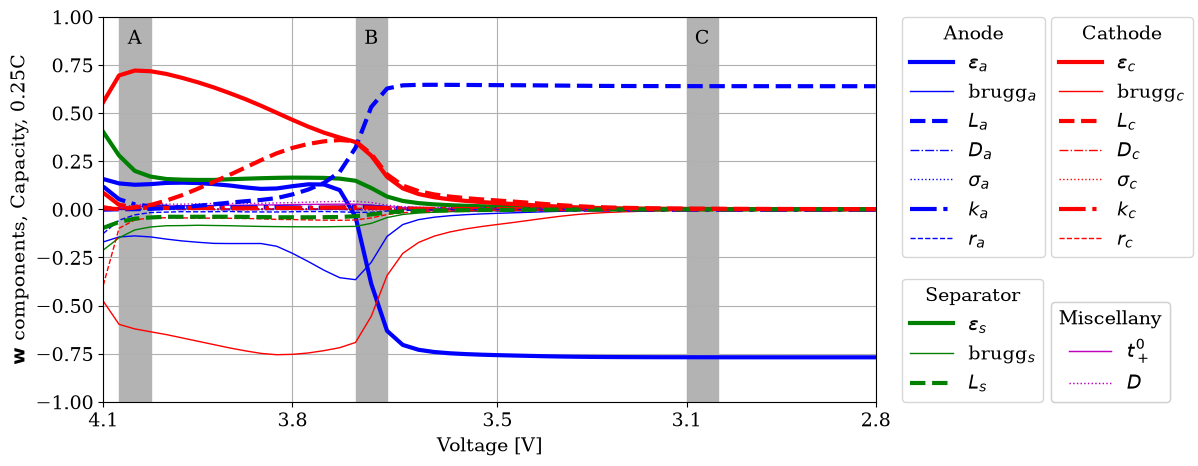

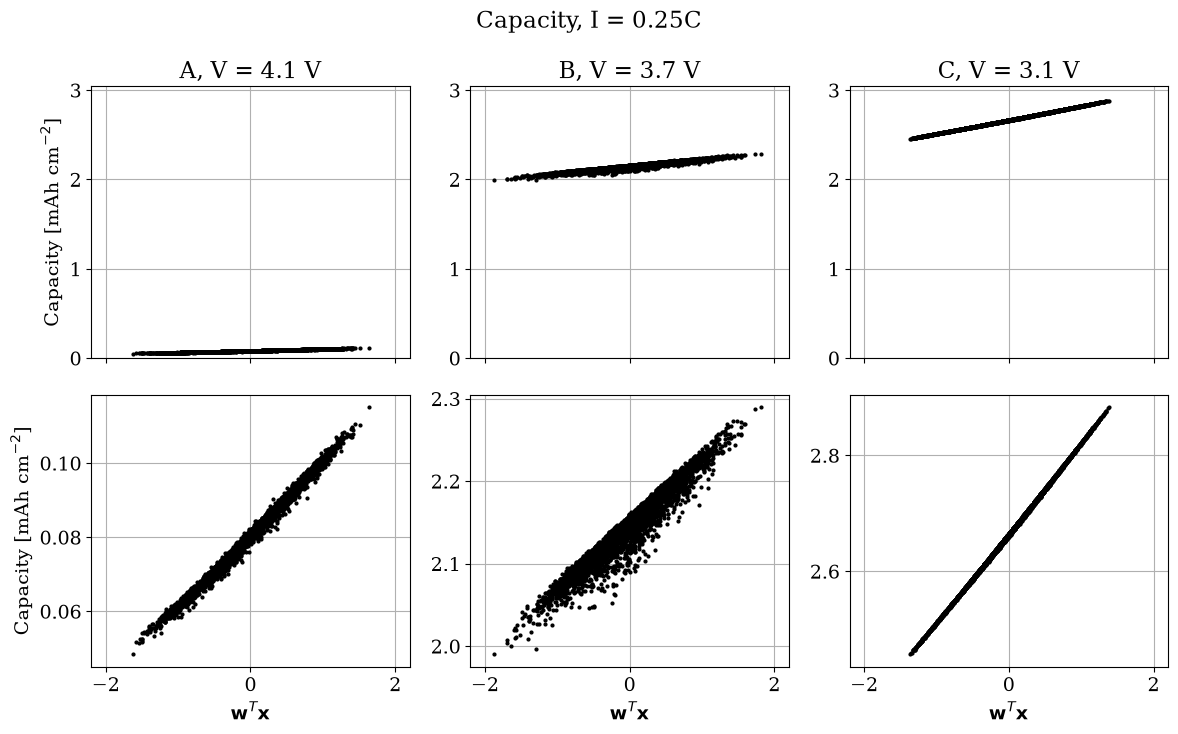

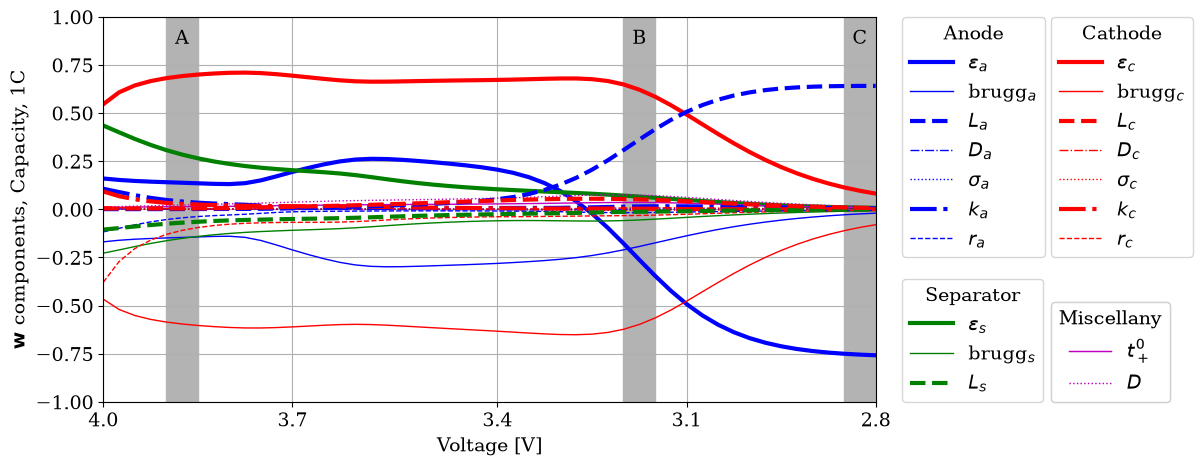

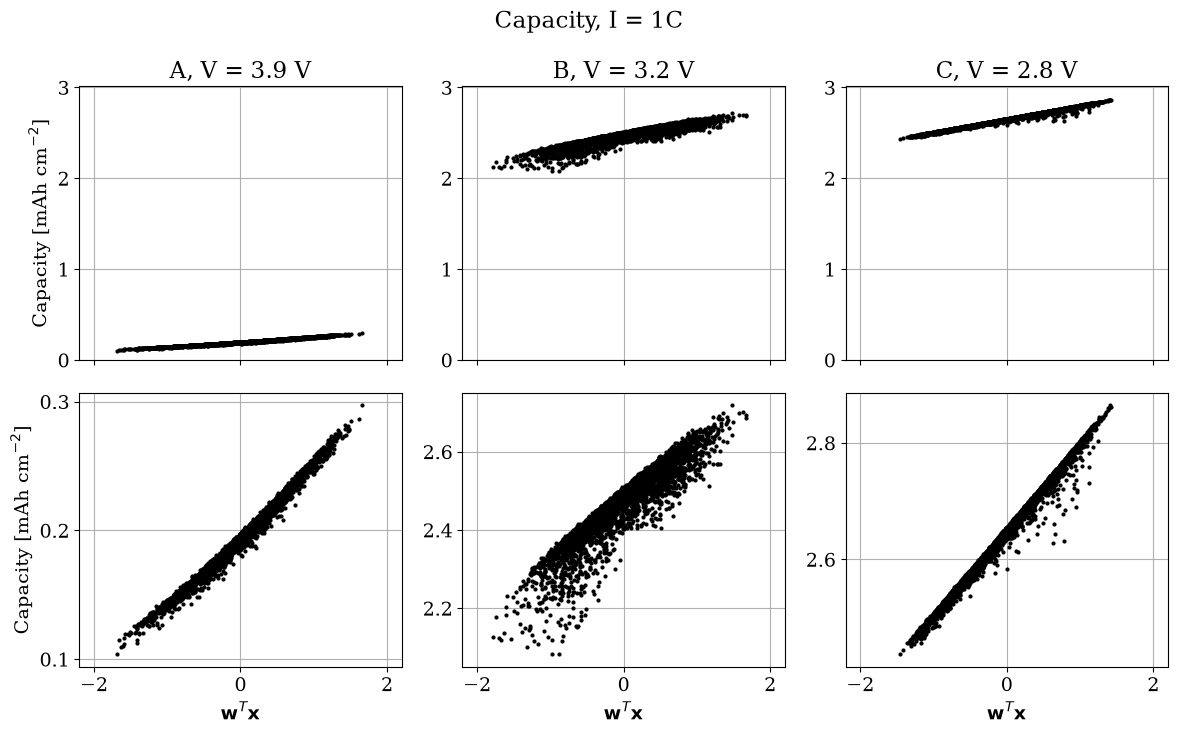

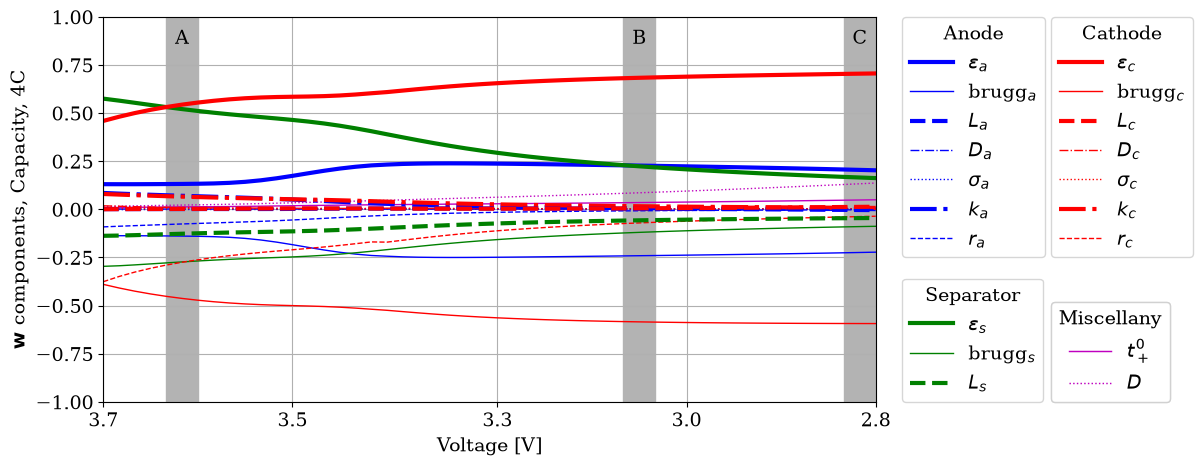

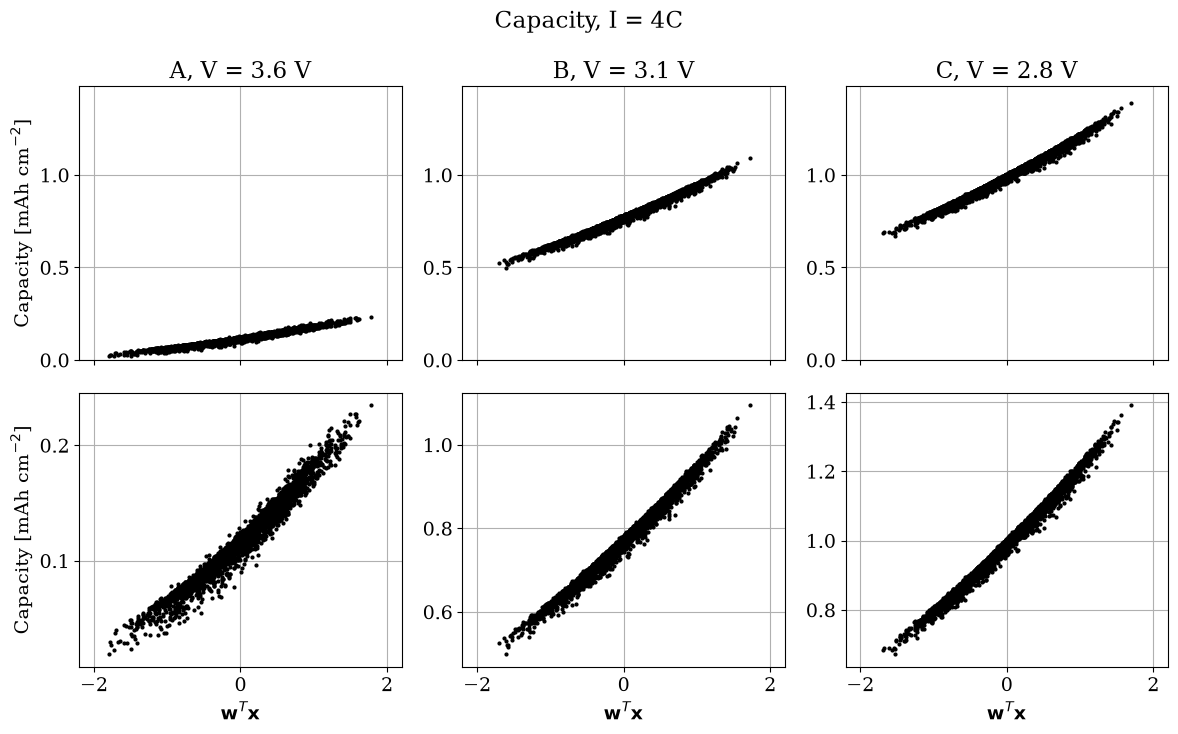

In [4]:
def r2(key, c):
    """R^2 of the straight-line fit in the summary plot at grid column c."""
    return np.corrcoef(X[key[1]] @ at(key, c), F[key][:, c])[0, 1]**2


def figures(qoi):
    for rate in bf.RATES:
        key = (qoi, rate)
        bf.plot_weights(qoi, rate, grid[key], grid[key][bf.COLS[qoi]], W[key])
        bf.plot_summaries(qoi, rate, grid[key], X[rate], F[key], [at(key, c) for c in bf.BANDS[key]])
        unit = ' V' if qoi == 'capacity' else ''
        print(f'{qoi} {rate}, straight-line R^2 of the summary plots: ' + ', '.join(
            f'{name} ({grid[key][c]:.2f}{unit}) {r2(key, c):.3f}' for c, name in zip(bf.BANDS[key], 'ABC')))


figures('capacity')

Each discharge rate has a plot showing the evolution of the components of $\mathbf w$ as voltage changes; the graphs below these are the summary plots, with the active variable $\mathbf w^T\mathbf x$ on the $x$-axis and capacity on the $y$-axis, each corresponding to the voltages labeled A, B, and C. The top row of summary plots for each discharge rate all have the same values on the $y$-axis, demonstrating the variation of capacity as voltage decreases; the bottom row shows the exact same data, but zoomed in to elucidate the trends of capacity as functions of the active variable.

Each summary plot shows at least a fairly tight trend, though variation around the trend varies by discharge rate and voltage. The tightest trend appears for discharge rate $0.25C$ and voltage 3.1 V, where a straight line fits with $R^2 = 1.000$, and the loosest for $1C$ and 3.2 V ($R^2 = 0.840$). The trends appear to be loose in regions where the relative importance of parameters is shifting rapidly; outside of these regions (all voltages for $4C$ and extreme voltages for $1C$ and $0.25C$), capacity is well approximated by a univariate function of the active variable. Two interesting observations of these graphs are that most of the parameters have components close to 0, indicating that they are unimportant in characterizing capacity, and that changes in the relative importance of parameters occur more smoothly as the discharge rate increases.

At $0.25C$ and 3.1 V, only two components are far from zero: the anode porosity $\epsilon_a$ ($-0.77$) and the anode length $L_a$ ($+0.64$), printed above. Increasing the anode porosity lowers the capacity there, and lengthening the anode raises it.

We'll now create similar plots for voltage as a function of time ([[1]](https://doi.org/10.1002/sam.11347) Figs. 5–7).

voltage 0.25C, straight-line R^2 of the summary plots: A (95.00) 0.989, B (23.00) 0.986, C (5.00) 0.983


voltage 1C, straight-line R^2 of the summary plots: A (95.00) 0.983, B (23.00) 0.979, C (5.00) 0.980


voltage 4C, straight-line R^2 of the summary plots: A (95.00) 0.943, B (23.00) 0.944, C (5.00) 0.947
input with the largest |w| component (number of grid points):
  capacity 0.25C: eps_a (32), brugg_c (12), eps_c (6)
   voltage 0.25C: eps_a (30), brugg_c (12), eps_c (6)
  capacity    1C: eps_c (37), eps_a (12), L_a (1)
   voltage    1C: eps_c (48)
  capacity    4C: eps_c (46), eps_s (4)
   voltage    4C: eps_s (43), D (5)
max |w| over the grid of D, D_a, D_c: capacity 0.25C 0.04/0.00/0.02; voltage 0.25C 0.03/0.00/0.00; capacity 1C 0.08/0.00/0.01; voltage 1C 0.06/0.00/0.01; capacity 4C 0.14/0.00/0.02; voltage 4C 0.60/0.00/0.03
4C voltage at A, B, C: A: eps_s +0.65, D -0.02, r_c -0.43; B: eps_s +0.61, D -0.47, r_c -0.34; C: eps_s +0.49, D -0.59, r_c -0.28


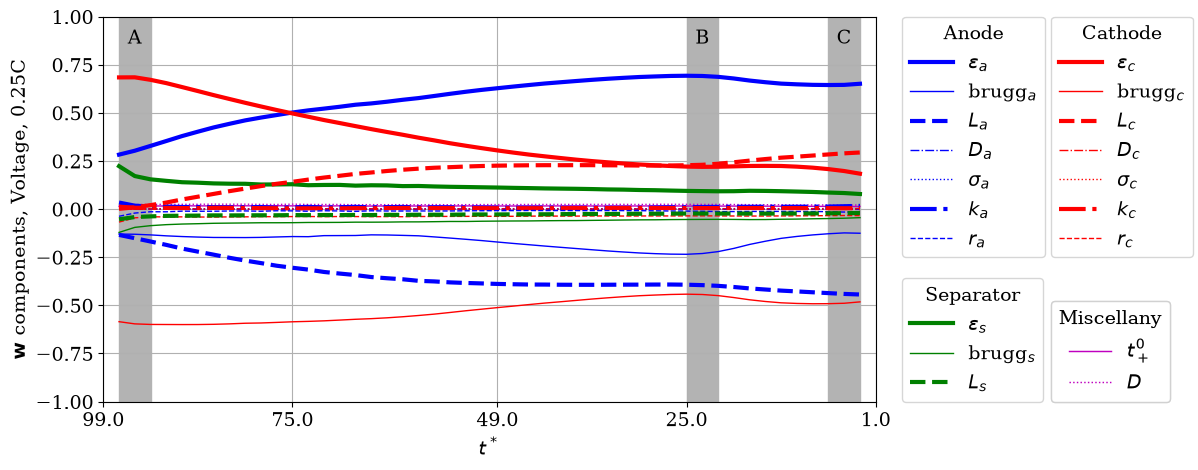

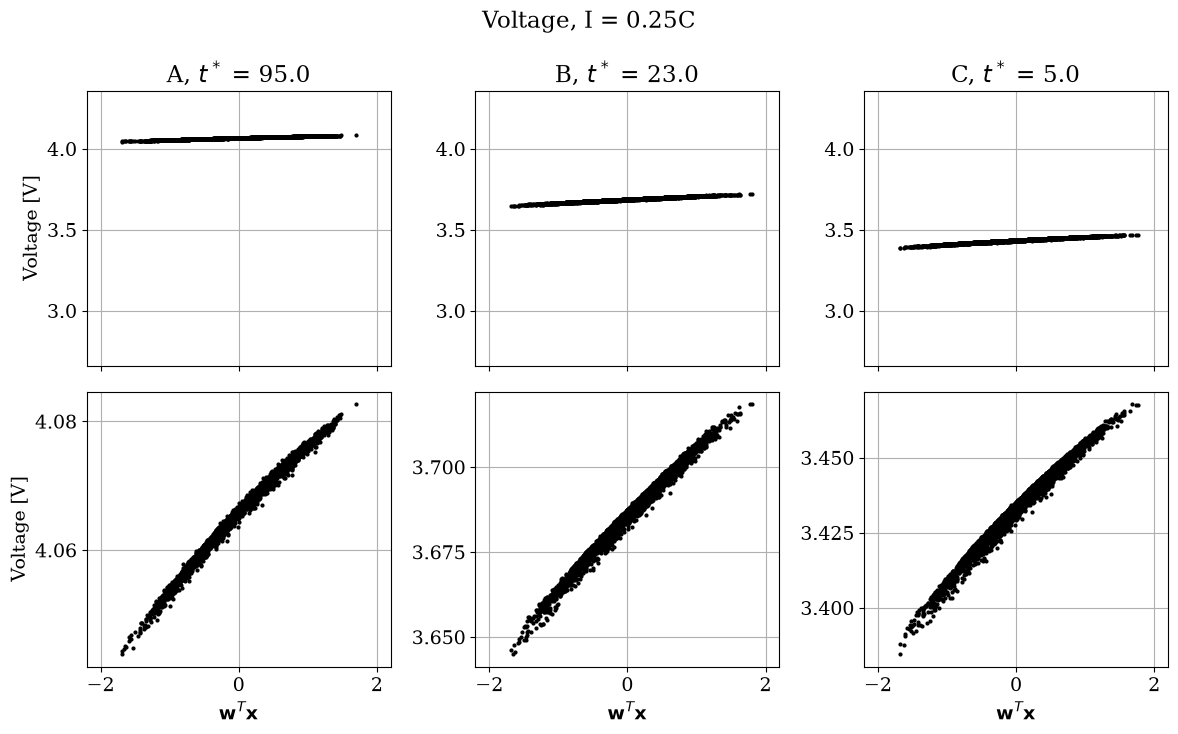

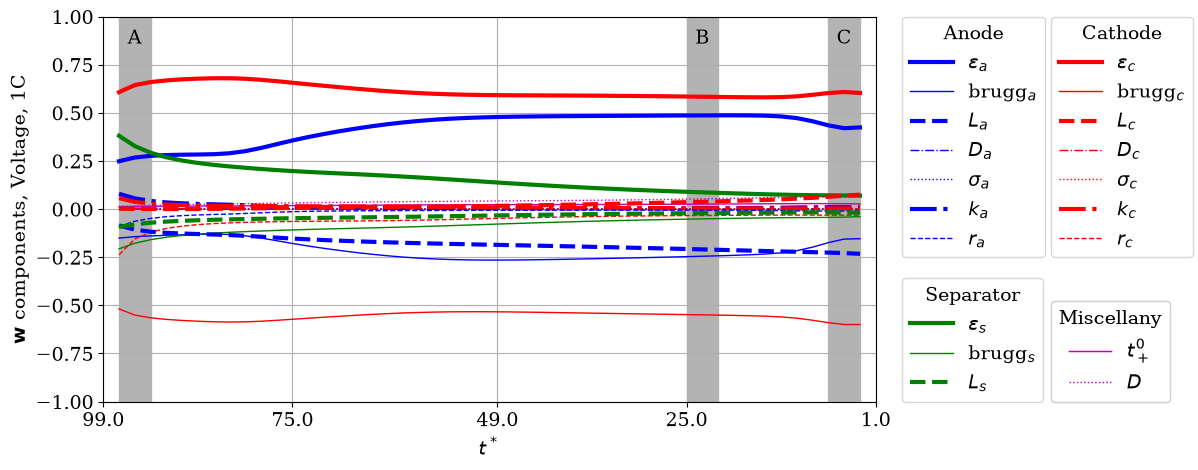

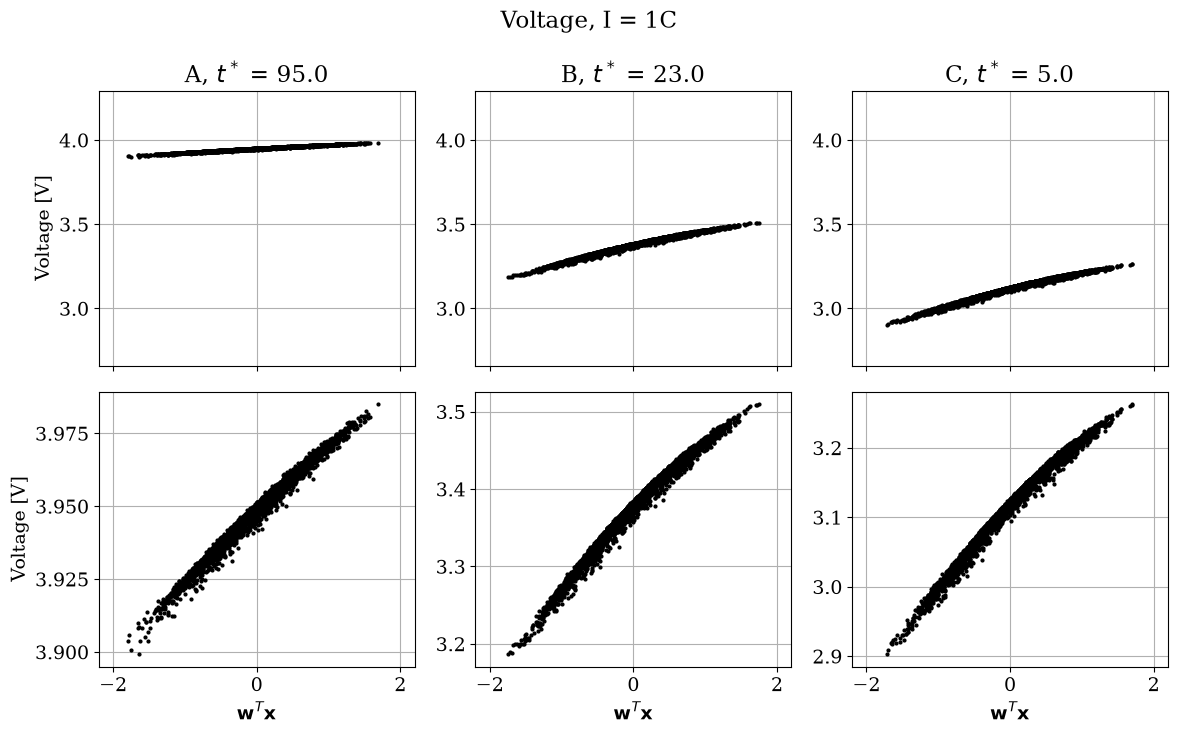

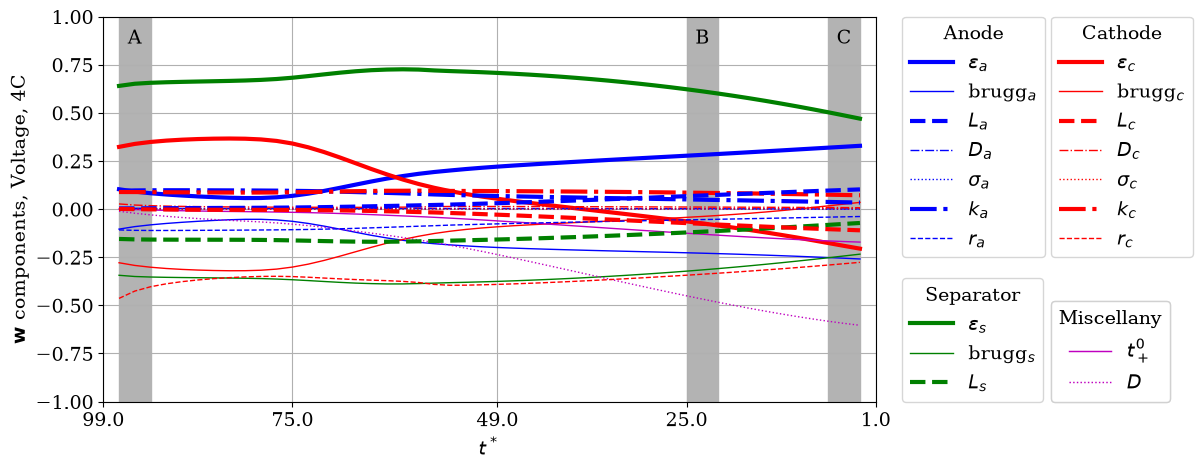

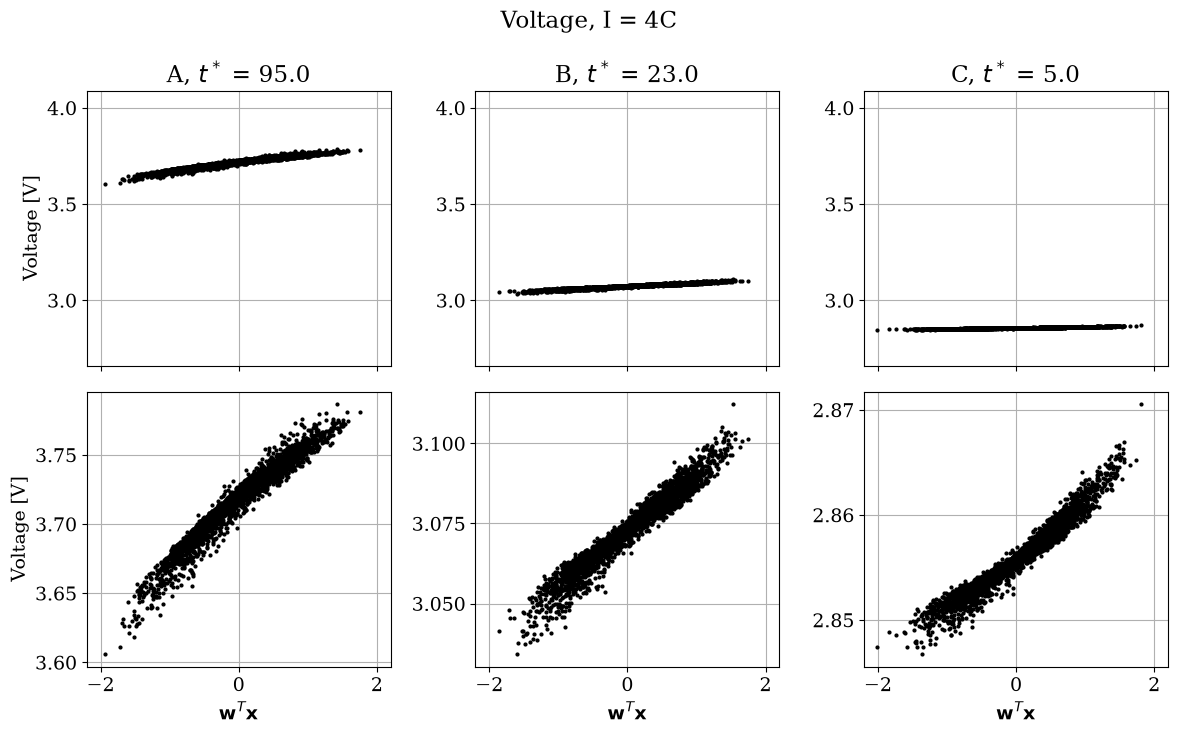

In [5]:
figures('voltage')

print('input with the largest |w| component (number of grid points):')
for key in QOIS:
    count = Counter(bf.NAMES[j] for j in np.abs(W[key]).argmax(axis=1))
    print(f'  {key[0]:>8} {key[1]:>5}: ' + ', '.join(f'{n} ({k})' for n, k in count.most_common()))
print('max |w| over the grid of D, D_a, D_c: ' + '; '.join(
    f'{q} {r} ' + '/'.join(f'{np.abs(W[q, r][:, j]).max():.2f}' for j in (7, 8, 9)) for q, r in QOIS))
print('4C voltage at A, B, C: ' + '; '.join(
    f'{name}: ' + ', '.join(f'{bf.NAMES[j]} {at(("voltage", "4C"), c)[j]:+.2f}' for j in (1, 7, 15))
    for c, name in zip(bf.BANDS['voltage', '4C'], 'ABC')))

We can see that every trend here is tight enough that voltage can reasonably be approximated as a univariate function of the active variable (straight-line $R^2$ between 0.94 and 0.99), and that the components of $\mathbf w$ change much less with time than the capacity components change with voltage. More parameters are important (have components far from 0) for voltage than for capacity.

Porosities, lengths and Bruggeman coefficients are the most important parameters at $0.25C$ and $1C$, for both capacity and voltage, and for capacity at $4C$: the largest component is always $\epsilon_a$, $\epsilon_c$, $\epsilon_s$, brugg$_c$ or $L_a$ (table above). The $4C$ voltage is different. There the separator porosity $\epsilon_s$ has the largest component early in the discharge, and as $t^*$ decreases (physical time increases), the salt diffusion coefficient $D$ becomes important: its component reaches $-0.59$ at $t^* = 5$ (C), where it is the largest. This is the only place where a diffusion parameter has a large component; for every other quantity, $|w_D|$ stays at or below 0.14, and the solid diffusion coefficients $D_a$ and $D_c$ stay at or below 0.03 everywhere. The cathode particle size $r_c$ also matters for the $4C$ voltage, with components between $-0.43$ and $-0.28$ at A, B and C.

### Algorithm 2: eigenvalues of the quadratic model

As a check on the one-dimensional structure, [[1]](https://doi.org/10.1002/sam.11347) Fig. 8 applies Algorithm 2 at the regions A, B and C of every quantity of interest. In v1 this is `ac.active_subspace(estimator="qphd")`. It fits the 210-coefficient quadratic model by least squares and takes the eigenpairs of $\mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$, where $\boldsymbol\Sigma$ is the covariance of the inputs. For $\mathbf x$ uniform on $[-1, 1]^{19}$, $\boldsymbol\Sigma = \mathbf I/3$. [[1]](https://doi.org/10.1002/sam.11347) eq. (14) prints $\mathbf g\mathbf g^T + \mathbf H^2$, which assumes $\boldsymbol\Sigma = \mathbf I$, but its Fig. 8 matches the $\mathbf I/3$ version: the values read off Fig. 8A are printed next to ours below. A large gap between the first two eigenvalues supports a one-dimensional active subspace.

v1 makes each eigenvector's largest component positive. We use `ac.orient(by="covariance")` to give the first eigenvector the sign of Algorithm 1 instead (cov$(\mathbf X\mathbf w_1, f) > 0$), and print its inner product with $\mathbf w$ from Algorithm 1.

                     lambda_1  lambda_2 log10 gap  w1 . w
capacity   0.25C A   3.91e-04  4.88e-06      1.90   1.000   paper Fig. 8A: 4.0e-04 6e-06
capacity   0.25C B   6.23e-03  8.74e-04      0.85   1.000   paper Fig. 8A: 5.0e-03 8e-04
capacity   0.25C C   2.40e-02  7.09e-06      3.53   1.000   paper Fig. 8A: 2.5e-02 7e-06
 voltage   0.25C A   1.29e-04  1.22e-06      2.02   1.000
 voltage   0.25C B   4.38e-04  1.06e-05      1.62   1.000
 voltage   0.25C C   5.48e-04  1.77e-05      1.49   1.000
capacity      1C A   3.03e-03  7.10e-05      1.63   1.000
capacity      1C B   2.92e-02  5.30e-03      0.74   0.979
capacity      1C C   2.15e-02  4.18e-04      1.71   1.000
 voltage      1C A   5.58e-04  1.59e-05      1.54   1.000
 voltage      1C B   9.53e-03  1.59e-04      1.78   1.000
 voltage      1C C   1.19e-02  1.79e-04      1.82   1.000
capacity      4C A   3.56e-03  2.01e-04      1.25   1.000
capacity      4C B   2.72e-02  4.85e-04      1.75   1.000
capacity      4C C   4.32e-02  4.82e-

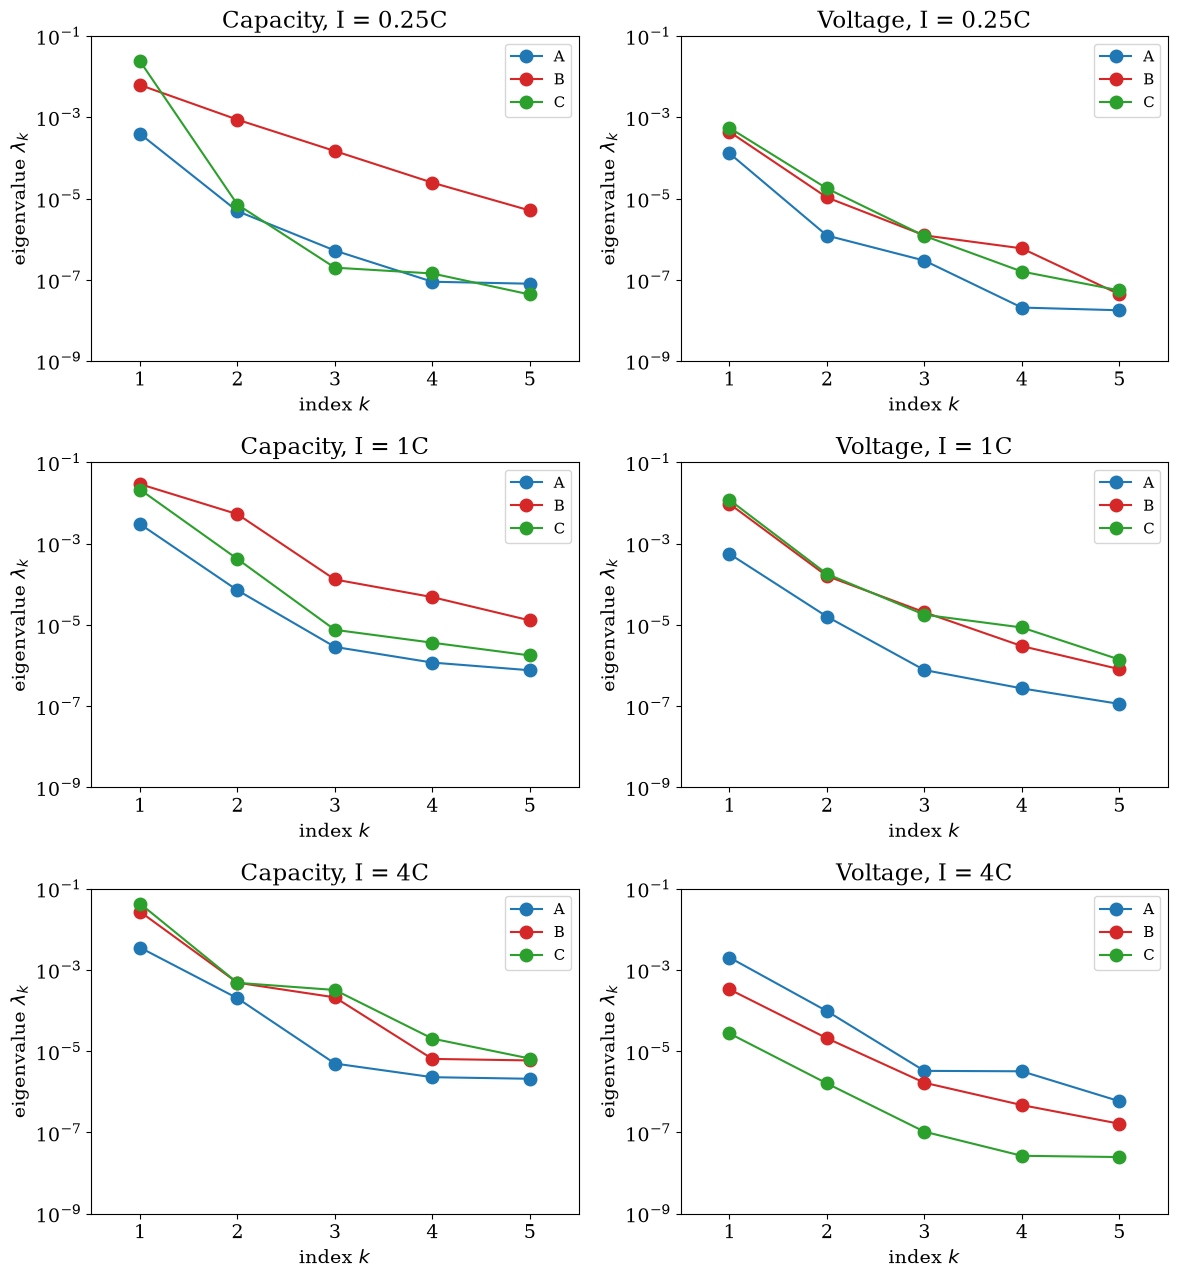

In [6]:
paper_fig8a = {'A': (4e-4, 6e-6), 'B': (5e-3, 8e-4), 'C': (2.5e-2, 7e-6)}   # lambda_1, lambda_2 read off [1] Fig. 8A
space = ac.Uniform.reference(19, names=bf.LABELS)
qphd = {}
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=ac.ValidityWarning)   # as for OLS: a heuristic on a uniform space
    for key in QOIS:
        for c in bf.BANDS[key]:
            f = F[key][:, c]
            sub = ac.active_subspace(X=X[key[1]], f=f, space=space, estimator='qphd', n=1)
            qphd[key, c] = ac.orient(sub, by='covariance', X=X[key[1]], f=f)

fig, axes = plt.subplots(3, 2, figsize=(12, 13))
print(f'{"":>16} {"":2} {"lambda_1":>9} {"lambda_2":>9} {"log10 gap":>9} {"w1 . w":>7}')
for i, rate in enumerate(bf.RATES):
    for j, qoi in enumerate(['capacity', 'voltage']):
        key, ax = (qoi, rate), axes[i, j]
        for c, name, color in zip(bf.BANDS[key], 'ABC', ['tab:blue', 'tab:red', 'tab:green']):
            s = qphd[key, c]
            ac.plotting.plot_eigenvalues(s, k_max=5, mark_dimension=False, ax=ax,
                                         line_kw={'color': color, 'label': name, 'markersize': 9})
            lam = np.abs(s.eigenvalues)
            print(f'{qoi:>8} {rate:>7} {name:2} {lam[0]:9.2e} {lam[1]:9.2e} {np.log10(lam[0] / lam[1]):9.2f} '
                  f'{s.W1[:, 0] @ at(key, c):7.3f}' + (f'   paper Fig. 8A: {paper_fig8a[name][0]:.1e} {paper_fig8a[name][1]:.0e}'
                                                     if key == ('capacity', '0.25C') else ''))
        ax.set_ylim(1e-9, 1e-1)
        ax.set_title(f'{qoi.capitalize()}, I = {rate}')
        ax.legend(fontsize=11)
fig.tight_layout()

For capacity at $0.25C$, the first two eigenvalues differ by about two, one, and three and a half orders of magnitude at A, B and C, as in [[1]](https://doi.org/10.1002/sam.11347) ("two, one, and nearly four"). The smallest gap is at B, where the summary plot has the most spread, and the largest at C, where the trend is a straight line. Of all eighteen cases, the smallest gap is for capacity at $1C$ at B (0.74), the loosest summary plot ($R^2 = 0.840$). In every case the first eigenvector of the quadratic model is close to $\mathbf w$ from Algorithm 1 (inner products in the last column).

### Bootstrap standard errors

Lastly, we plot the bootstrap standard errors of the components of $\mathbf w$ (as a function of voltage for capacity and as a function of $t^*$ for voltage) to examine the robustness of our method ([[1]](https://doi.org/10.1002/sam.11347) Fig. 9). The standard error is the standard deviation of each component over 100 bootstrap replicates of $\mathbf w$, each computed from the runs resampled with replacement and signed to agree with $\mathbf w$.

In v1, `ac.active_subspace(..., nboot=100, bootstrap_vectors=1, rng=rng)` stores such replicates for one grid point at a time. Doing that at all 294 grid points takes several minutes. For the curves, `bf.bootstrap_se` instead draws one resample of the runs per replicate and solves the least-squares problem for all grid points of a quantity at once. We run the v1 bootstrap at the 18 points A, B and C, compare the two, and use the v1 replicates for the band plot further below. The two use different draws, so they agree only up to bootstrap noise. The vertical axes are not clipped.

largest component SE at the 18 points A, B, C, v1 bootstrap / shared-resample bootstrap: 0.88 to 1.06


                  max SE         at region SE < 0.005
capacity   0.25C  0.0051     3.67 V      B      99.9%
 voltage   0.25C  0.0028     3.00        C     100.0%
capacity      1C  0.0099     3.15 V      B      79.4%
 voltage      1C  0.0029     9.00        -     100.0%
capacity      4C  0.0045     3.72 V      -     100.0%
 voltage      4C  0.0051    63.00        -      97.3%
largest standard error overall: 0.0099


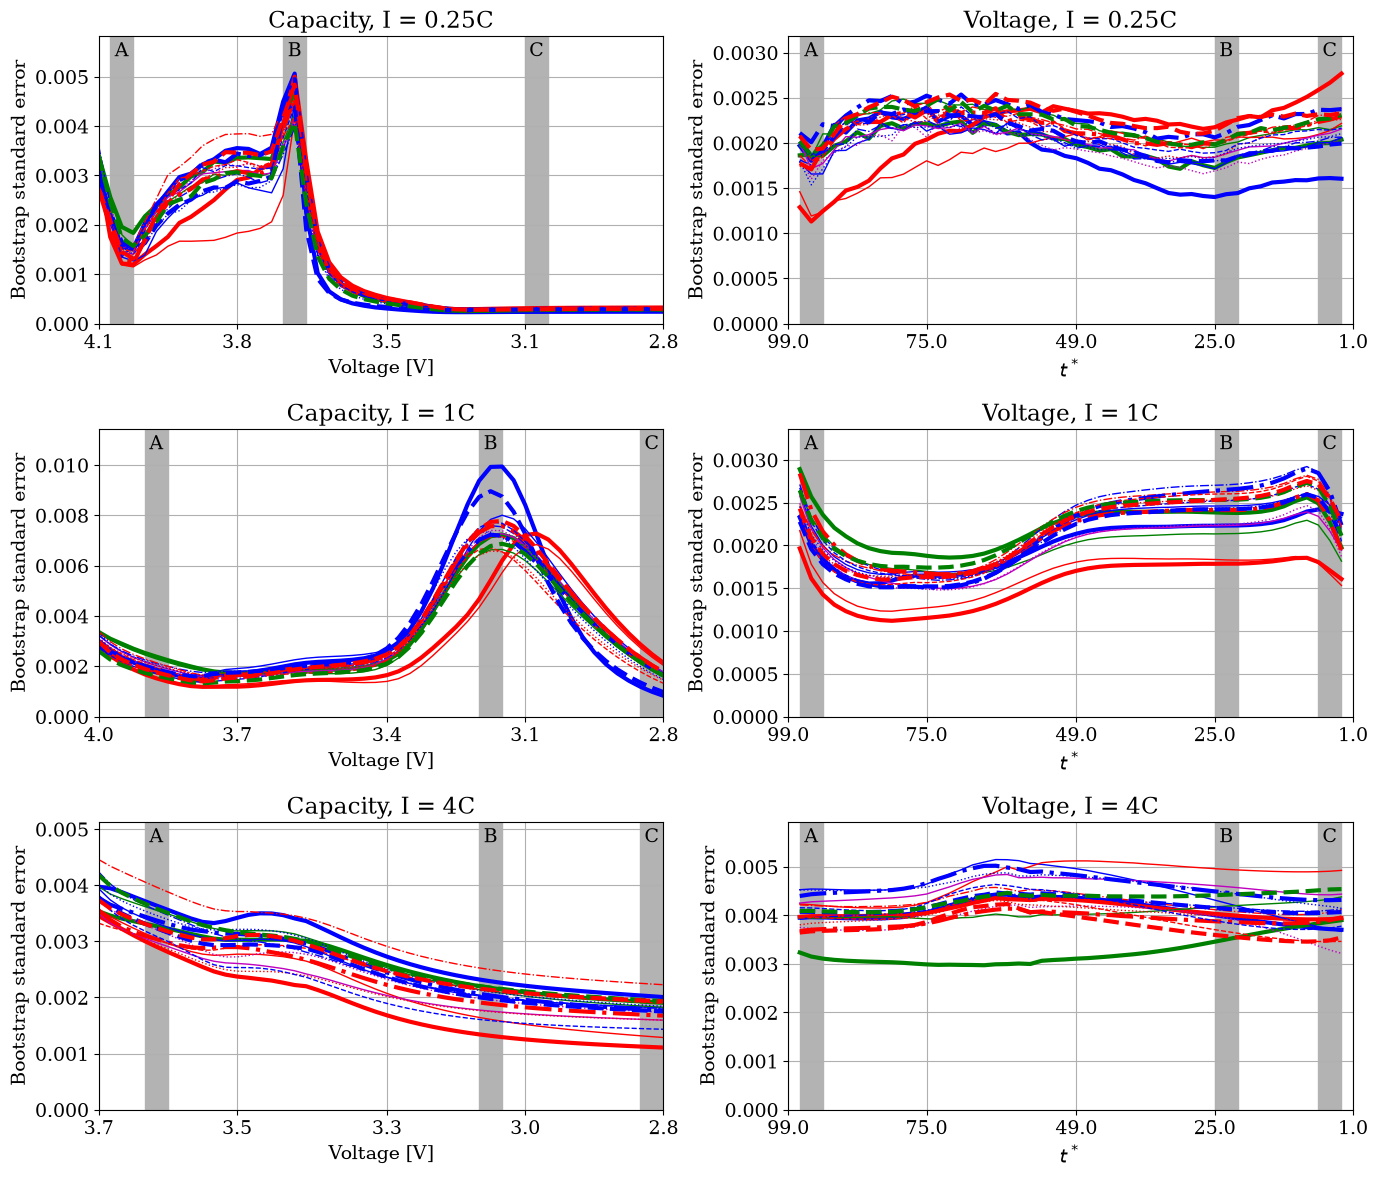

In [7]:
boot = {}
for key in QOIS:
    for c in bf.BANDS[key]:
        boot[key, c] = bf.weights(X[key[1]], F[key][:, [c]], nboot=100, rng=rng)[0]
SE = {key: bf.bootstrap_se(X[key[1]], F[key][:, bf.COLS[key[0]]], W[key], rng) for key in QOIS}
ratio = [b.bootstrap_eigenvectors[:, :, 0].std(axis=0).max() / SE[key][bf.row(key[0], c)].max()
         for (key, c), b in boot.items()]
print(f'largest component SE at the 18 points A, B, C, v1 bootstrap / shared-resample bootstrap: '
      f'{min(ratio):.2f} to {max(ratio):.2f}')

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for i, rate in enumerate(bf.RATES):
    for j, qoi in enumerate(['capacity', 'voltage']):
        key = (qoi, rate)
        bf.plot_se(axes[i, j], qoi, rate, grid[key], grid[key][bf.COLS[qoi]], SE[key])
        axes[i, j].set_ylabel('Bootstrap standard error')
fig.tight_layout()

print(f'{"":>16} {"max SE":>7}  {"at":>9} {"region":>6} {"SE < 0.005":>10}')
for key in QOIS:
    k = np.unravel_index(SE[key].argmax(), SE[key].shape)[0]
    c = bf.COLS[key[0]][k]
    region = ''.join(name for b, name in zip(bf.BANDS[key], 'ABC') if abs(c - b) <= 1) or '-'
    unit = ' V' if key[0] == 'capacity' else ''
    print(f'{key[0]:>8} {key[1]:>7} {SE[key].max():7.4f}  {grid[key][c]:7.2f}{unit:2} {region:>6} '
          f'{(SE[key] < 0.005).mean():10.1%}')
print(f'largest standard error overall: {max(s.max() for s in SE.values()):.4f}')

All bootstrap standard errors are low: about 0.01 or less for capacity at $1C$, and mostly below 0.005 everywhere else (table above). This indicates that the estimated components would likely not change much if the sampled points happened to be different. The 2016 version of this figure clipped its axes at 0.010, which can hide the largest values at $1C$; the value depends on the bootstrap draw. There are 2 notable spikes in standard error: region B for both capacity with $0.25C$ and capacity with $1C$. These correspond to the loose trends in the summary plots, the smallest eigenvalue gaps of the quadratic model, and the points where the relative sensitivities of parameters are shifting rapidly. They could be caused by regime changes in the physical system that cause behavior that either can't be captured by our linear-model heuristic or can't be captured by a 1-dimensional subspace.

v1 can also draw the bootstrap replicates of $\mathbf w$ directly, as a 95% percentile band per component (`ac.plotting.plot_eigenvectors(..., interval="percentile")`). Below is $\mathbf w$ for capacity at $1C$ at A, B and C. On this scale the bands are thin at all three points; the printed widths show that the widest band at B is about three times the widest at A and C.

A (3.90 V): widest 95% band 0.009
B (3.18 V): widest 95% band 0.034
C (2.83 V): widest 95% band 0.010


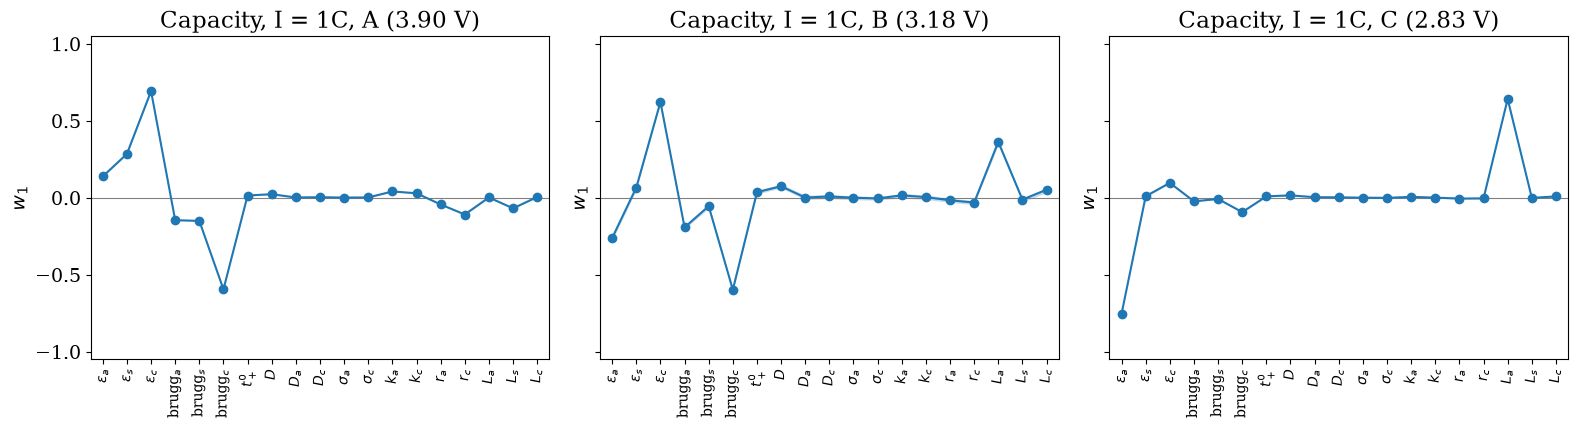

In [8]:
key = ('capacity', '1C')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, c, name in zip(axes, bf.BANDS[key], 'ABC'):
    s = boot[key, c]
    ac.plotting.plot_eigenvectors(s, indices=[0], interval='percentile', ax=[ax])
    ax.set_title(f'Capacity, I = 1C, {name} ({grid[key][c]:.2f} V)')
    ax.tick_params(axis='x', labelsize=10, labelrotation=90)
    band = ac.bootstrap_interval(s.bootstrap_eigenvectors[:, :, 0], kind='percentile', level=0.95)
    print(f'{name} ({grid[key][c]:.2f} V): widest 95% band {np.ptp(band, axis=0).max():.3f}')
fig.tight_layout()

### Notes on the published paper

Checking this notebook against the published version of [[1]](https://doi.org/10.1002/sam.11347) found the following. The notebook follows the data in each case.

- p. 259: "region c in Figures 9A and 9C" should read region b. The standard-error peaks are in region B (table above), as the paper's own Fig. 9 shows.
- pp. 253–254: the text says that at $0.25C$ and 3.1 V the anode porosity's component is positive and that the other large component belongs to the anode Bruggeman coefficient. Fig. 2A and the data give $\epsilon_a = -0.77$ and $L_a = +0.64$, with brugg$_a$ near 0 (printed above). The paper's §3.2.1 ("Increasing porosity … lowers capacity") agrees with the negative sign.
- p. 250: capacity is called "inversely proportional to the cell voltage". It decreases as the voltage falls, but not as $1/V$: at $0.25C$ the mean capacity goes from 0.01 mAh cm$^{-2}$ at 4.13 V to 2.67 mAh cm$^{-2}$ at 2.8 V (printed at the top).
- p. 252: every fit is said to use $N = 3600$ runs. The 2016 code dropped 4C run 1538, and this notebook drops 4C runs 1538 and 2969 ($N = 3598$).
- Table 1, p. 250: the particle sizes $r_a$ and $r_c$ are listed as Normal, but their stored values are uniform (see "About the data"). Which one is right is not known.
- Eq. (14), p. 246: $\mathbf g\mathbf g^T + \mathbf H^2$ takes the input covariance to be $\mathbf I$; for the uniform inputs it is $\mathbf I/3$, and Fig. 8 matches $\mathbf g\mathbf g^T + \mathbf H\mathbf H/3$.

In [9]:
print(f'Total run time: {time.perf_counter() - t_start:.0f} s')

Total run time: 61 s
